# DATA 620 Project 1:

## Dataset

Twitch Gamers social network from SNAP (Rozemberczki & Sarkar, 2021). It's a mutual follower network of Twitch streamers, where nodes are streamers and edges mean two streamers follow each other back. The features file includes a categorical flag for each streamer that we'll use for this project : whether theyre a Twitch affiliate (yes/no). Its a status Twitch grants once a streamer hits certain audience and engagement thresholds.

## Plan

1. Build a connected sample using a breadth firstsnowball search.
2. Compute degree centrality and eigenvector centrality for every node in the sample.
3. Compare both measures between affiliate and non affiliate streamers using summary stats and a t-test.
4. Look at the top-ranked streamers under each measure to see if the two measures agree on who matters most.

## Link 

https://youtu.be/oAfiqykhegM

## 1. Setup

In [1]:
from collections import defaultdict, deque

import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats

## 2. Load the data and build a sample

Same BFS approach from before. We start at one streamer and walk outward through real follower connections until 500 users are collected. Keeps the sample connected instead of scattering disconnected fragments.

In [2]:
def build_sample(seed_node, target_n=500):
    sample_ids = {seed_node}
    queue = deque([seed_node])
    while queue and len(sample_ids) < target_n:
        node = queue.popleft()
        for neighbor in adjacency[node]:
            if neighbor not in sample_ids:
                sample_ids.add(neighbor)
                queue.append(neighbor)
                if len(sample_ids) >= target_n:
                    break

    sample_edges = edges[edges["numeric_id_1"].isin(sample_ids) & edges["numeric_id_2"].isin(sample_ids)]
    G = nx.from_pandas_edgelist(sample_edges, "numeric_id_1", "numeric_id_2")
    if not nx.is_connected(G):
        largest = max(nx.connected_components(G), key=len)
        G = G.subgraph(largest).copy()
    return G

edges = pd.read_csv("large_twitch_edges.csv")
features = pd.read_csv("large_twitch_features.csv").set_index("numeric_id")

adjacency = defaultdict(list)
for a, b in zip(edges["numeric_id_1"], edges["numeric_id_2"]):
    adjacency[a].append(b)
    adjacency[b].append(a)

G = build_sample(12345)
print("Nodes     :", G.number_of_nodes())
print("Edges     :", G.number_of_edges())
print("Connected :", nx.is_connected(G))

Nodes     : 500
Edges     : 2107
Connected : True


## 3. Calculate degree centrality and eigenvector centrality

Both are built into NetworkX so this is just two easy function calls. We'll join the results onto the features table so we can see affiliate status next to both the centrality scores

In [5]:
degree_centrality = nx.degree_centrality(G)
eigenvector_centrality = nx.eigenvector_centrality(G, max_iter=1000)

sample_features = features.loc[list(G.nodes())].copy()
sample_features["degree_centrality"] = pd.Series(degree_centrality)
sample_features["eigenvector_centrality"] = pd.Series(eigenvector_centrality)

sample_features[["affiliate", "degree_centrality", "eigenvector_centrality"]].head()

,affiliate,degree_centrality,eigenvector_centrality
numeric_id,,,
98343,0,0.008016,0.018703
3635,0,0.016032,0.028521
116648,0,0.082164,0.105267
89631,1,0.028056,0.036260
155127,0,0.905812,0.406110


## 4. Compare across affiliate status

In [6]:
sample_features.groupby("affiliate")[["degree_centrality", "eigenvector_centrality"]].agg(["mean", "median"])

degree_centrality           eigenvector_centrality          
                       mean    median                   mean    median
affiliate                                                             
0                  0.023549  0.008016               0.035880  0.023920
1                  0.009135  0.006012               0.025499  0.018226

In [7]:
affiliates = sample_features[sample_features["affiliate"] == 1]
non_affiliates = sample_features[sample_features["affiliate"] == 0]

degree_t, degree_p = stats.ttest_ind(affiliates["degree_centrality"], non_affiliates["degree_centrality"], equal_var=False)
eigen_t, eigen_p = stats.ttest_ind(affiliates["eigenvector_centrality"], non_affiliates["eigenvector_centrality"], equal_var=False)

print(f"Degree centrality t-test      : t = {degree_t:.2f} p = {degree_p:.2e}")
print(f"Eigenvector centrality t-test : t = {eigen_t:.2f} p = {eigen_p:.2e}")

Degree centrality t-test      : t = -3.55 p = 4.44e-04
Eigenvector centrality t-test : t = -3.84 p = 1.44e-04


Both differences are statistically significant with p under 0.05, and show the same thing. non affiliate streamers in this sample have higher average degree and eigenvector centrality than affiliates. That's the opposite of what I originally expected going into the proposal. I figured affiliate status would track with being more connected not less.

Im guessing affiliate status is granted based on Twitchs own criteria, mainly around view count and how consistent someones streaming is and not directly on the follower network. A streamer could possible hit those target thresholds through things like getting featured, playing a popular game, or just streaming consistently, without necessarily being connected in a dense web of other streamers. Meanwhile some well connected non affiliates in the sample might be newer or smaller streamers who are tightly networked with their peers but havent crossed Twitchs affiliate thresholds yet.

## 5. Do the two measures agree on whos most important

In [8]:
top_degree = sample_features.sort_values("degree_centrality", ascending=False).head(5)
top_eigen = sample_features.sort_values("eigenvector_centrality", ascending=False).head(5)

print("Top 5 by degree centrality:")
print(top_degree[["degree_centrality", "affiliate"]])
print()
print("Top 5 by eigenvector centrality:")
print(top_eigen[["eigenvector_centrality", "affiliate"]])

correlation = sample_features["degree_centrality"].corr(sample_features["eigenvector_centrality"])
print(f"Correlation between degree and eigenvector centrality: {correlation:.3f}")

Top 5 by degree centrality:
            degree_centrality  affiliate
numeric_id                              
155127               0.905812          0
125642               0.330661          0
64605                0.288577          0
78367                0.172345          0
146235               0.154309          0

Top 5 by eigenvector centrality:
            eigenvector_centrality  affiliate
numeric_id                                   
155127                    0.406110          0
125642                    0.266270          0
64605                     0.261490          0
78367                     0.170665          0
53444                     0.142132          0
Correlation between degree and eigenvector centrality: 0.884


In this sample the two measures mostly agree, the same handful of streamers show up at the top of both lists and none of them are affiliates. The overall correlation between degree and eigenvector centrality came out to 0.884 which tells us that this isnt just a coincidence at the top,  they follow each other closely across the whole sample. That makes sense given the shape of this network from Assignment 2 a few big hub accounts dominate both how many direct connections they have and how connected their connections are so there isn’t really much room for the two measures to disagree.

## 6. Visualize the comparison

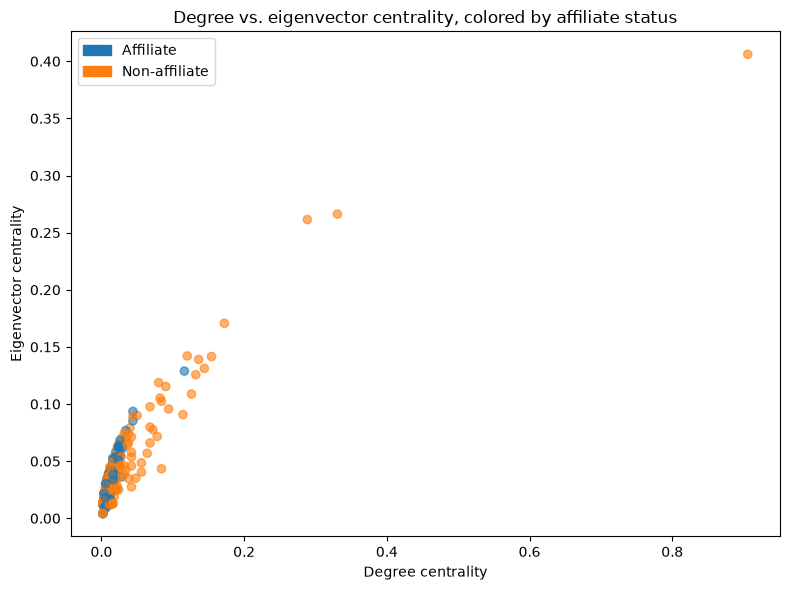

In [9]:
colors = ["tab:blue" if a == 1 else "tab:orange" for a in sample_features["affiliate"]]

plt.figure(figsize=(8, 6))
plt.scatter(sample_features["degree_centrality"], sample_features["eigenvector_centrality"],
            c=colors, alpha=0.6)
plt.xlabel("Degree centrality")
plt.ylabel("Eigenvector centrality")
plt.title("Degree vs. eigenvector centrality, colored by affiliate status")

import matplotlib.patches as mpatches
handles = [mpatches.Patch(color="tab:blue", label="Affiliate"),
           mpatches.Patch(color="tab:orange", label="Non-affiliate")]
plt.legend(handles=handles)
plt.tight_layout()
plt.show()

The non affiliate stretch further out toward the high end of both measures while the affiliate points stay more clustered toward the lower left. That matches the t-test results. non-affiliates include the most network central streamers in this sample.


## 7. Correcting for the outlier

Node 155127 has a degree centrality over 0.9, which means it’s connected to more than 90% of the entire sample, making it an extreme outlier. I want to see if this node is single handedly driving the  difference between affiliates and non-affiliates. We'll checjk if removing it and re running both t-tests changes the results.


In [11]:
without_outlier = sample_features.drop(index=155127)

aff_no_outlier = without_outlier[without_outlier["affiliate"] == 1]
non_aff_no_outlier = without_outlier[without_outlier["affiliate"] == 0]

degree_t2, degree_p2 = stats.ttest_ind(aff_no_outlier["degree_centrality"], non_aff_no_outlier["degree_centrality"], equal_var=False)
eigen_t2, eigen_p2 = stats.ttest_ind(aff_no_outlier["eigenvector_centrality"], non_aff_no_outlier["eigenvector_centrality"], equal_var=False)

print(f"Without node 155127:")
print(f"Degree centrality t-test      : t = {degree_t2:.2f}, p = {degree_p2:.2e}")
print(f"Eigenvector centrality t-test : t = {eigen_t2:.2f}, p = {eigen_p2:.2e}")

Without node 155127:
Degree centrality t-test      : t = -4.68, p = 4.26e-06
Eigenvector centrality t-test : t = -3.86, p = 1.30e-04


Even after removing the outlier node both t-tests stayed significant. The eigenvector centrality result barely moved, and the degree centrality result actually got stronger. So this isn’t a case of one extreme node skewing the whole comparison, the difference between affiliates and non-affiliates holds up even with the most connected streamer in the sample taken out.

## 8. Checking robustness across many samples

Alright so everything so far is based on one 500 node sample from one starting seed. To check whether this result holds up more generally, I want to repeat the whole process (sample, compute centralities, t-test) across 50 different random seed nodes, and look at how often the result pointed the same direction and how often it was statistically significant.

In [12]:
import random

def run_sample_and_test(seed_node):
    sample_graph = build_sample(seed_node)

    deg = nx.degree_centrality(sample_graph)
    eig = nx.eigenvector_centrality(sample_graph, max_iter=1000)

    sf = features.loc[list(sample_graph.nodes())].copy()
    sf["degree_centrality"] = pd.Series(deg)
    sf["eigenvector_centrality"] = pd.Series(eig)

    aff = sf[sf["affiliate"] == 1]
    non = sf[sf["affiliate"] == 0]

    dt, dp = stats.ttest_ind(aff["degree_centrality"], non["degree_centrality"], equal_var=False)
    et, ep = stats.ttest_ind(aff["eigenvector_centrality"], non["eigenvector_centrality"], equal_var=False)
    return dt, dp, et, ep

random.seed(123)
all_node_ids = list(adjacency.keys())
random_seeds = random.sample(all_node_ids, 50)

results = [run_sample_and_test(s) for s in random_seeds]
robustness = pd.DataFrame(results, columns=["degree_t", "degree_p", "eigen_t", "eigen_p"])

print(f"Degree centrality: same direction in {(robustness['degree_t'] < 0).mean():.0%} of samples, "
      f"significant in {(robustness['degree_p'] < 0.05).mean():.0%}")
print(f"Eigenvector centrality: same direction in {(robustness['eigen_t'] < 0).mean():.0%} of samples, "
      f"significant in {(robustness['eigen_p'] < 0.05).mean():.0%}")

Degree centrality: same direction in 98% of samples, significant in 90%
Eigenvector centrality: same direction in 98% of samples, significant in 90%


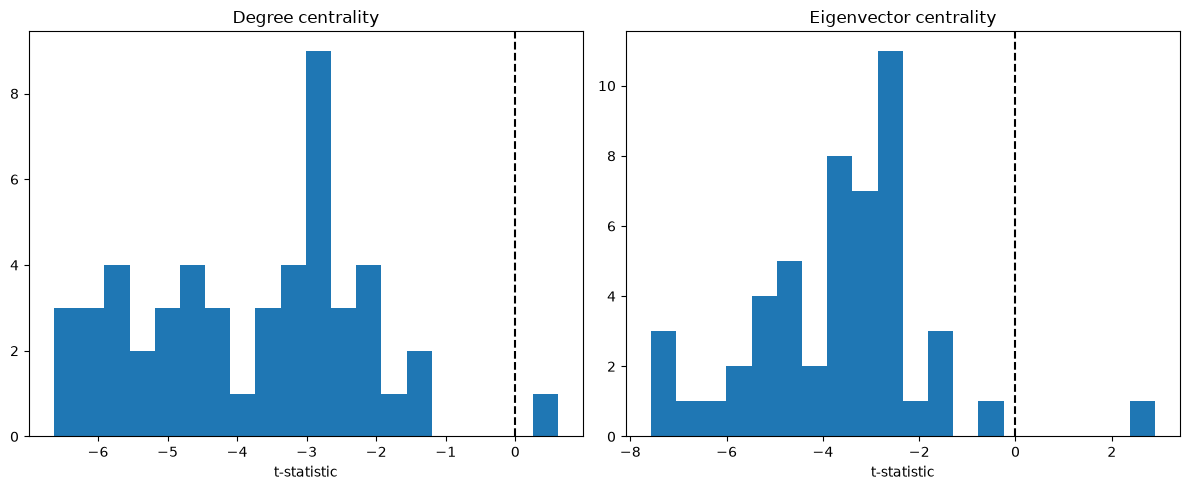

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].hist(robustness["degree_t"], bins=20)
axes[0].axvline(0, color="black", linestyle="--")
axes[0].set_title("Degree centrality")
axes[0].set_xlabel("t-statistic")

axes[1].hist(robustness["eigen_t"], bins=20)
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Eigenvector centrality")
axes[1].set_xlabel("t-statistic")

plt.tight_layout()
plt.show()

Well that confirms what I got initially wasnt a fluke. Across 50 different random samples the result held up. Degree centrality showed non affiliates scoring higher in 98% of samples and that difference was statistically significant on its own in 90% of them. Eigenvector centrality showed the same thing in 98% of samples significant in 90%. Both plots are centered on the negative with only a small number on the other side, most likely cases where the BFS walk happened to gather in an affiliate hub early on. 

## Summary

- Both degree centrality and eigenvector centrality were significantly higher for non-affiliates than affiliates, the opposite of what I expected going in
- The two measures agreed closely with each other, correlated at 0.884, with the same handful of hub streamers topping both rankings
- Removing the single most extreme outlier node didn’t weaken the result, it actually got stronger without it
- Running the test across 50 different random samples confirmed the pattern holds up consistently, not just in the one sample I started with
